In [5]:
import os
from pathlib import Path
from dotenv import load_dotenv

BASE_DIR = Path(
    "/home/abi/vison-model/"
    "Vision-Based Product Attribution and BOM Mapping"
)

ENV_PATH = BASE_DIR / ".env"

if not ENV_PATH.exists():
    raise FileNotFoundError(f".env file not found: {ENV_PATH}")

load_dotenv(ENV_PATH, override=False)

# Check configuration without displaying secrets
required_vars = [
    "BEDROCK_BASE_URL",
    "BEDROCK_API_KEY",
    "AWS_REGION",
]

for name in required_vars:
    value = os.getenv(name)
    print(f"{name}: {'Loaded' if value else 'MISSING'}")

print("Environment loading complete.")

BEDROCK_BASE_URL: Loaded
BEDROCK_API_KEY: Loaded
AWS_REGION: Loaded
Environment loading complete.


In [6]:
import os
import boto3

REGION = os.getenv("AWS_REGION", "us-east-1")
MODEL_ID = "amazon.nova-2-multimodal-embeddings-v1:0"
EMBEDDING_DIMENSION = 1024

# Configure Bedrock bearer-token authentication
os.environ["AWS_BEARER_TOKEN_BEDROCK"] = os.environ["BEDROCK_API_KEY"]

bedrock = boto3.client(
    "bedrock-runtime",
    region_name=REGION
)

print("Bedrock client initialized.")
print("Region:", REGION)
print("Model:", MODEL_ID)
print("Embedding dimension:", EMBEDDING_DIMENSION)

Bedrock client initialized.
Region: us-east-1
Model: amazon.nova-2-multimodal-embeddings-v1:0
Embedding dimension: 1024


In [7]:
import pandas as pd

CATALOG_PATH = BASE_DIR / "data" / "combined" / "prototype_catalog.csv"
CROPS_DIR = BASE_DIR / "data" / "combined" / "crops"

df = pd.read_csv(CATALOG_PATH)

# Normalize IDs for consistent ChromaDB indexing
df["crop_id"] = df["crop_id"].astype(str)

print("Catalog loaded successfully!")
print("Total images:", len(df))
print("Unique crop IDs:", df["crop_id"].nunique())
print("Missing image paths:", (~df["crop_path"].map(
    lambda p: Path(str(p)).is_file()
)).sum())

print("\nClass distribution:")
display(df["class_name"].value_counts().to_frame("count"))

print("\nSample metadata:")
display(df[["crop_id", "crop_path", "class_name", "sku"]].head())

Catalog loaded successfully!
Total images: 10269
Unique crop IDs: 10269
Missing image paths: 0

Class distribution:


,count
class_name,
Nut,2846
Gear,2718
Bolt,2548
Bearing,2157



Sample metadata:


,crop_id,crop_path,class_name,sku
0,CROP-000001,/home/abi/vison-model/Vision-Based Product Att...,Bolt,BLT-000001
1,CROP-000002,/home/abi/vison-model/Vision-Based Product Att...,Bolt,BLT-000002
2,CROP-000003,/home/abi/vison-model/Vision-Based Product Att...,Nut,NUT-000001
3,CROP-000004,/home/abi/vison-model/Vision-Based Product Att...,Nut,NUT-000002
4,CROP-000005,/home/abi/vison-model/Vision-Based Product Att...,Nut,NUT-000003


In [8]:
import chromadb

NOVA_DB_PATH = BASE_DIR / "data" / "chroma_nova_db"
NOVA_DB_PATH.mkdir(parents=True, exist_ok=True)

nova_client = chromadb.PersistentClient(
    path=str(NOVA_DB_PATH)
)

nova_collection = nova_client.get_or_create_collection(
    name="mechanical_parts_nova",
    metadata={
        "description": "Mechanical part image embeddings using Amazon Nova",
        "embedding_model": MODEL_ID,
        "embedding_dimension": EMBEDDING_DIMENSION,
        "hnsw:space": "cosine",
    },
)

print("Nova database initialized.")
print("Database path:", NOVA_DB_PATH)
print("Collection:", nova_collection.name)
print("Already indexed:", nova_collection.count())

Nova database initialized.
Database path: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/chroma_nova_db
Collection: mechanical_parts_nova
Already indexed: 85


In [9]:
import base64
import json
from pathlib import Path

def generate_nova_embedding(image_path):
    image_path = Path(image_path)

    image_format = image_path.suffix.lower().lstrip(".")
    if image_format == "jpg":
        image_format = "jpeg"

    image_bytes = image_path.read_bytes()

    request_body = {
        "taskType": "SINGLE_EMBEDDING",
        "singleEmbeddingParams": {
            "embeddingPurpose": "GENERIC_INDEX",
            "embeddingDimension": EMBEDDING_DIMENSION,
            "image": {
                "format": image_format,
                "source": {
                    "bytes": base64.b64encode(image_bytes).decode("utf-8")
                }
            }
        }
    }

    response = bedrock.invoke_model(
        modelId=MODEL_ID,
        body=json.dumps(request_body),
        contentType="application/json",
        accept="application/json",
    )

    result = json.loads(response["body"].read())
    embedding = result["embeddings"][0]["embedding"]

    if len(embedding) != EMBEDDING_DIMENSION:
        raise ValueError(
            f"Expected {EMBEDDING_DIMENSION} dimensions, "
            f"received {len(embedding)}"
        )

    return embedding

print("Nova embedding function defined.")

Nova embedding function defined.


In [10]:
# Get all IDs currently stored in the Nova collection
indexed_ids = set()

for batch in nova_collection.get(
    include=[],
    limit=1000
)["ids"]:
    indexed_ids.add(batch)

print("Total catalog images:", len(df))
print("Indexed in Nova:", len(indexed_ids))

# Find catalog images that haven't been indexed
remaining_df = df[
    ~df["crop_id"].astype(str).isin(indexed_ids)
].copy()

print("Remaining images:", len(remaining_df))

print("\nRemaining images by class:")
display(
    remaining_df["class_name"]
    .value_counts()
    .to_frame("remaining_images")
)

Total catalog images: 10269
Indexed in Nova: 85
Remaining images: 10184

Remaining images by class:


,remaining_images
class_name,
Nut,2797
Gear,2718
Bolt,2512
Bearing,2157


In [11]:
import time
from tqdm.auto import tqdm

BATCH_SIZE = 25
MAX_RETRIES = 3
RETRY_DELAY_SECONDS = 2

# Keep a record of failures for later investigation
failed_images = []

# Verify that IDs are unique in the catalog
assert df["crop_id"].is_unique, "Duplicate crop IDs found in catalog!"

print("Indexing configuration ready.")
print("Batch size:", BATCH_SIZE)
print("Max retries per image:", MAX_RETRIES)
print("Images to process:", len(remaining_df))
print("Current indexed count:", nova_collection.count())

Indexing configuration ready.
Batch size: 25
Max retries per image: 3
Images to process: 10184
Current indexed count: 85


In [12]:
import time
from tqdm.auto import tqdm

BATCH_SIZE = 25
MAX_RETRIES = 3

# Fetch every existing ID using pagination
indexed_ids = set()
offset = 0
page_size = 1000

while True:
    page = nova_collection.get(
        limit=page_size,
        offset=offset,
        include=[]
    )

    page_ids = page["ids"]
    indexed_ids.update(page_ids)

    if len(page_ids) < page_size:
        break

    offset += len(page_ids)

# Calculate remaining work
remaining_df = df[
    ~df["crop_id"].astype(str).isin(indexed_ids)
].copy()

failed_images = []

print("Already indexed:", len(indexed_ids))
print("Images remaining:", len(remaining_df))

# Process images and save each batch
for start in tqdm(range(0, len(remaining_df), BATCH_SIZE)):
    batch = remaining_df.iloc[start:start + BATCH_SIZE]

    batch_ids = []
    batch_embeddings = []
    batch_metadatas = []

    for _, row in batch.iterrows():
        crop_id = str(row["crop_id"])

        for attempt in range(MAX_RETRIES):
            try:
                embedding = generate_nova_embedding(row["crop_path"])

                metadata = {
                    "crop_id": crop_id,
                    "class_name": str(row["class_name"]),
                    "class_id": int(row["class_id"]),
                    "sku": str(row["sku"]),
                    "manufacturer": str(row["manufacturer"]),
                    "manufacturer_part_number": str(row["manufacturer_part_number"]),
                    "data_origin": str(row["data_origin"]),
                    "verification_status": str(row["verification_status"]),
                    "crop_path": str(row["crop_path"]),
                }

                batch_ids.append(crop_id)
                batch_embeddings.append(embedding)
                batch_metadatas.append(metadata)
                break

            except Exception as exc:
                if attempt < MAX_RETRIES - 1:
                    time.sleep(2 ** attempt)
                else:
                    failed_images.append({
                        "crop_id": crop_id,
                        "crop_path": str(row["crop_path"]),
                        "error": str(exc),
                    })

    if batch_ids:
        nova_collection.add(
            ids=batch_ids,
            embeddings=batch_embeddings,
            metadatas=batch_metadatas,
        )

    # Show progress occasionally
    if (start // BATCH_SIZE + 1) % 10 == 0:
        print(
            f"\nProcessed batch {start // BATCH_SIZE + 1}; "
            f"ChromaDB count: {nova_collection.count()}; "
            f"Failures so far: {len(failed_images)}"
        )

    time.sleep(0.2)

print("\nIndexing run finished.")
print("Total indexed:", nova_collection.count())
print("Failed images:", len(failed_images))

Already indexed: 85
Images remaining: 10184


  0%|          | 0/408 [00:00<?, ?it/s]


Processed batch 10; ChromaDB count: 335; Failures so far: 0

Processed batch 20; ChromaDB count: 585; Failures so far: 0

Processed batch 30; ChromaDB count: 835; Failures so far: 0

Processed batch 40; ChromaDB count: 1085; Failures so far: 0

Processed batch 50; ChromaDB count: 1335; Failures so far: 0

Processed batch 60; ChromaDB count: 1585; Failures so far: 0

Processed batch 70; ChromaDB count: 1835; Failures so far: 0

Processed batch 80; ChromaDB count: 2085; Failures so far: 0

Processed batch 90; ChromaDB count: 2335; Failures so far: 0

Processed batch 100; ChromaDB count: 2585; Failures so far: 0

Processed batch 110; ChromaDB count: 2835; Failures so far: 0

Processed batch 120; ChromaDB count: 3085; Failures so far: 0

Processed batch 130; ChromaDB count: 3335; Failures so far: 0

Processed batch 140; ChromaDB count: 3585; Failures so far: 0

Processed batch 150; ChromaDB count: 3835; Failures so far: 0

Processed batch 160; ChromaDB count: 4085; Failures so far: 0

Pro

In [13]:
# Check the final collection size
total_indexed = nova_collection.count()

print("========== NOVA INDEX STATUS ==========")
print("Expected catalog images:", len(df))
print("Images indexed:", total_indexed)
print("Images remaining:", max(0, len(df) - total_indexed))

# Inspect a few stored records
sample = nova_collection.get(
    limit=5,
    include=["metadatas"]
)

print("\nSample indexed records:")

for crop_id, metadata in zip(sample["ids"], sample["metadatas"]):
    print(
        f"{crop_id} | "
        f"Class: {metadata['class_name']} | "
        f"SKU: {metadata['sku']}"
    )

========== NOVA INDEX STATUS ==========
Expected catalog images: 10269
Images indexed: 10269
Images remaining: 0

Sample indexed records:
CROP-000001 | Class: Bolt | SKU: BLT-000001
CROP-000002 | Class: Bolt | SKU: BLT-000002
CROP-000003 | Class: Nut | SKU: NUT-000001
CROP-000004 | Class: Nut | SKU: NUT-000002
CROP-000005 | Class: Nut | SKU: NUT-000003


In [14]:
import random
import numpy as np
from collections import defaultdict
from tqdm.auto import tqdm

# Reproducible evaluation sample
random.seed(42)

EVAL_SIZE = 200
K_VALUES = [1, 3, 5, 10]

eval_df = df.sample(
    n=min(EVAL_SIZE, len(df)),
    random_state=42
).reset_index(drop=True)

precision_scores = defaultdict(list)

for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    query_id = str(row["crop_id"])
    query_class = str(row["class_name"])

    # Retrieve the query embedding
    query_record = nova_collection.get(
        ids=[query_id],
        include=["embeddings"]
    )

    query_embedding = query_record["embeddings"][0].tolist()

    # Retrieve extra neighbors because the query image itself may appear
    results = nova_collection.query(
        query_embeddings=[query_embedding],
        n_results=11,
        include=["metadatas", "distances"]
    )

    # Exclude the query image itself
    neighbors = [
        (crop_id, metadata)
        for crop_id, metadata in zip(
            results["ids"][0],
            results["metadatas"][0]
        )
        if crop_id != query_id
    ]

    for k in K_VALUES:
        top_k = neighbors[:k]

        if len(top_k) == k:
            relevant = sum(
                metadata["class_name"] == query_class
                for _, metadata in top_k
            )
            precision_scores[k].append(relevant / k)

print("\n===== NOVA CLASS-LEVEL RETRIEVAL =====")

for k in K_VALUES:
    score = np.mean(precision_scores[k]) * 100
    print(f"Precision@{k}: {score:.2f}%")

  0%|          | 0/200 [00:00<?, ?it/s]


===== NOVA CLASS-LEVEL RETRIEVAL =====
Precision@1: 97.00%
Precision@3: 96.83%
Precision@5: 95.50%
Precision@10: 93.75%


Query image: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/crops/bearing/CROP-000344.jpg
Image dimensions: (138, 189)


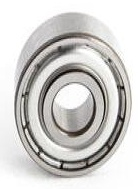

In [15]:
from pathlib import Path
from PIL import Image
from IPython.display import display

QUERY_IMAGE_PATH = Path(
    "/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/crops/bearing/CROP-000344.jpg"
)

if not QUERY_IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Image not found: {QUERY_IMAGE_PATH}")

query_image = Image.open(QUERY_IMAGE_PATH).convert("RGB")

print("Query image:", QUERY_IMAGE_PATH)
print("Image dimensions:", query_image.size)

display(query_image)

In [16]:
query_embedding = generate_nova_embedding(QUERY_IMAGE_PATH)

results = nova_collection.query(
    query_embeddings=[query_embedding],
    n_results=5,
    include=["metadatas", "distances"]
)

print("Query embedding dimensions:", len(query_embedding))
print("\nTop 5 similar catalog images:\n")

for i, (metadata, distance) in enumerate(
    zip(results["metadatas"][0], results["distances"][0]),
    start=1
):
    print(
        f"{i}. {metadata.get('crop_id')} | "
        f"Class: {metadata.get('class_name')} | "
        f"SKU: {metadata.get('sku')} | "
        f"Cosine distance: {distance:.4f}"
    )

Query embedding dimensions: 1024

Top 5 similar catalog images:

1. CROP-000344 | Class: Bearing | SKU: BRG-000002 | Cosine distance: -0.0000
2. CROP-002963 | Class: Bearing | SKU: BRG-001339 | Cosine distance: 0.0696
3. CROP-003506 | Class: Bearing | SKU: BRG-001881 | Cosine distance: 0.0703
4. CROP-000585 | Class: Bearing | SKU: BRG-000067 | Cosine distance: 0.0717
5. CROP-001960 | Class: Bearing | SKU: BRG-000343 | Cosine distance: 0.0720


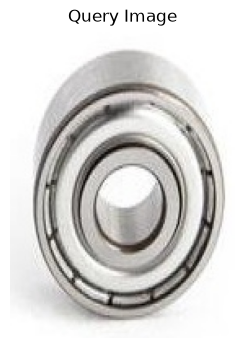

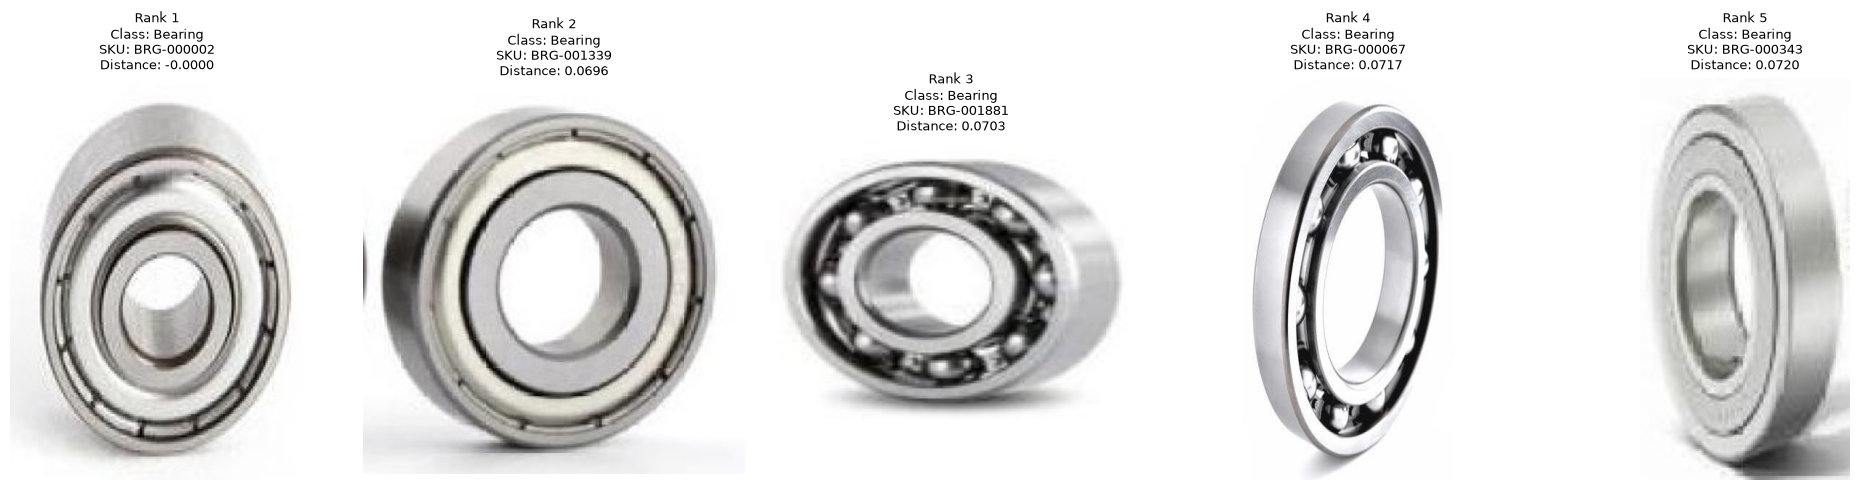

In [17]:
from PIL import Image as PILImage
from IPython.display import display
import matplotlib.pyplot as plt

# Display query image
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(PILImage.open(QUERY_IMAGE_PATH))
ax.set_title("Query Image")
ax.axis("off")
plt.show()

# Display top 5 retrieved catalog images
metadatas = results["metadatas"][0]
distances = results["distances"][0]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, (metadata, distance, ax) in enumerate(
    zip(metadatas, distances, axes), start=1
):
    image_path = metadata.get("crop_path")

    if image_path and Path(image_path).is_file():
        ax.imshow(PILImage.open(image_path))
    else:
        ax.text(0.5, 0.5, "Image not found", ha="center", va="center")

    ax.set_title(
        f"Rank {i}\n"
        f"Class: {metadata.get('class_name')}\n"
        f"SKU: {metadata.get('sku')}\n"
        f"Distance: {distance:.4f}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()